# 04 - Análise exploratória (EDA)

**Objetivo:** entender os dados antes de modelar. Cada pergunta aqui serve pra uma decisão das próximas etapas: que features criar, qual métrica usar e onde cortar treino e teste.

Leio `data/processed/dengue_clima_semanal.csv`, a tabela da etapa 4 (uma linha por semana, casos + clima do ERA5). As 20 semanas abertas aparecem nos gráficos, mas ficam fora das contas, porque os números delas ainda mudam.

Uma regra pra toda a EDA: ela descreve e levanta hipóteses usando a série inteira. Escolher um lag ou uma feature olhando o período que vai virar teste seria usar informação do futuro, então essas escolhas só são confirmadas com dados de treino na etapa 7.

Perguntas:
1. Em que época do ano os casos sobem?
2. Os casos da semana passada explicam os desta?
3. Quantas semanas depois da chuva os casos sobem?
4. E a temperatura e a umidade?
5. Como os casos se distribuem?
6. O que teve de diferente em 2022?

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

# Tabela final da etapa 4: uma linha por semana, casos + clima
dengue = pd.read_csv("../data/processed/dengue_clima_semanal.csv", parse_dates=["data_iniSE"])

# SE vem como AAAASS (ex.: 202216 = semana 16 de 2022)
# // é divisão inteira e % é o resto, igual Math.floor(SE / 100) e SE % 100 no JS
dengue["ano"] = dengue["SE"] // 100
dengue["semana_do_ano"] = dengue["SE"] % 100

# As 20 semanas abertas ainda vão mudar: aparecem nos gráficos, mas ficam fora das contas
fechadas = dengue[~dengue["semana_aberta"]].copy()

print("Semanas:", len(dengue), "| Fechadas:", len(fechadas), "| Abertas:", dengue["semana_aberta"].sum())
dengue.head(3)

Semanas: 619 | Fechadas: 599 | Abertas: 20


,data_iniSE,SE,casos,casos_est,semana_aberta,chuva_mm,temp_media,temp_min,temp_max,umidade_media,horas_era5,chuva_mm_a312,temp_media_a312,temp_min_a312,temp_max_a312,umidade_media_a312,horas_a312,ano,semana_do_ano
0,2015-01-04,201501,50,50.0,False,30.3,27.99,22.5,35.0,74.17,168,0.8,26.99,21.3,34.6,72.10,168.0,2015,1
1,2015-01-11,201502,34,34.0,False,0.9,29.75,24.4,36.0,63.55,168,0.0,28.45,22.6,36.3,65.07,168.0,2015,2
2,2015-01-18,201503,51,51.0,False,29.3,27.92,23.1,36.3,75.29,168,0.0,27.47,22.2,36.1,70.54,168.0,2015,3


## 1. Sazonalidade

Em que época do ano os casos sobem, e o pico cai sempre no mesmo período? Comparo os anos alinhados pela semana epidemiológica, com a mediana de cada semana como "ano típico" (mediana, e não média, porque o surto de 2022 puxaria a média sozinho).

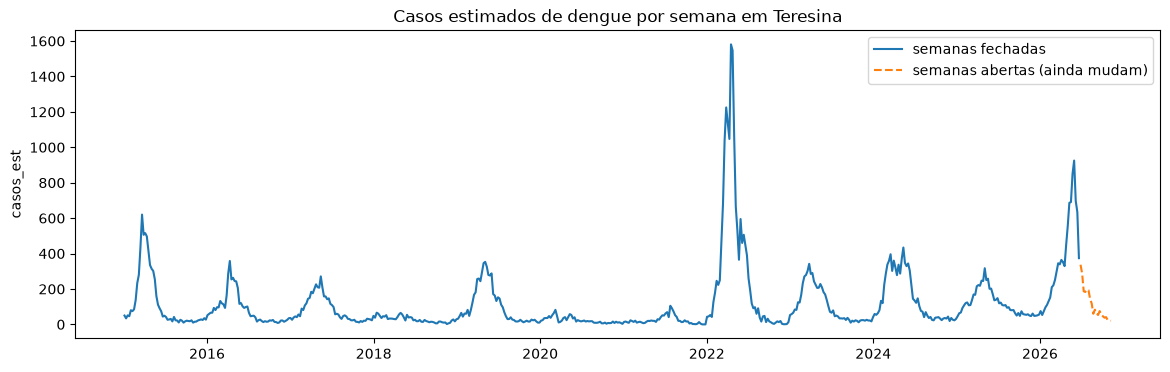

In [2]:
# A série inteira: semanas fechadas em linha cheia, abertas tracejadas
abertas = dengue[dengue["semana_aberta"]]

fig, eixo = plt.subplots(figsize=(14, 4))
eixo.plot(fechadas["data_iniSE"], fechadas["casos_est"], label="semanas fechadas")
eixo.plot(abertas["data_iniSE"], abertas["casos_est"], linestyle="--", label="semanas abertas (ainda mudam)")
eixo.set_title("Casos estimados de dengue por semana em Teresina")
eixo.set_ylabel("casos_est")
eixo.legend()
plt.show()

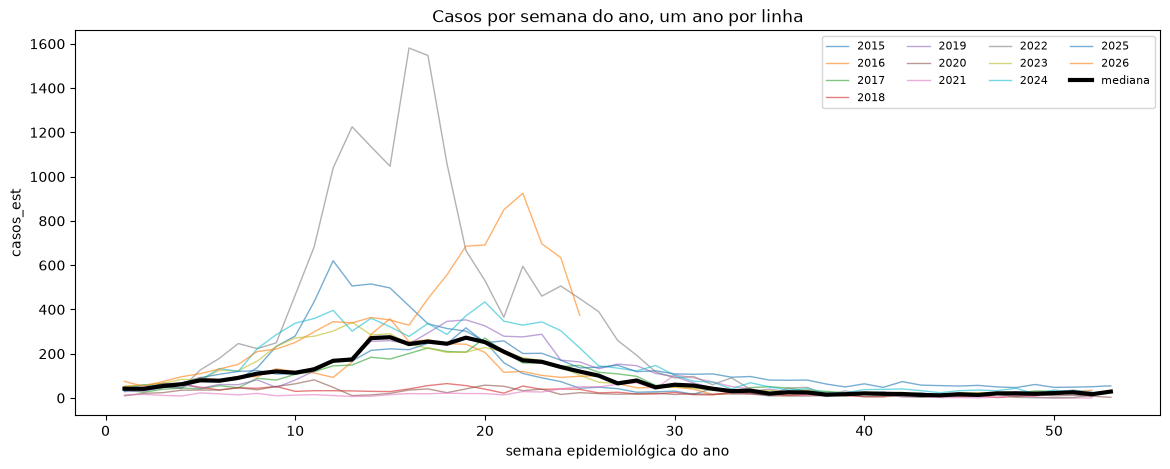

In [3]:
# Cada ano vira uma linha fina, alinhada pela semana do ano (1 a 53)
# Se o pico cair sempre no mesmo trecho, as linhas sobem juntas
fig, eixo = plt.subplots(figsize=(14, 5))

for ano in sorted(fechadas["ano"].unique()):
    do_ano = fechadas[fechadas["ano"] == ano]
    eixo.plot(do_ano["semana_do_ano"], do_ano["casos_est"], linewidth=1, alpha=0.6, label=str(ano))

# A mediana por semana do ano (GROUP BY semana_do_ano): o ano "típico"
# Mediana e não média porque o surto de 2022 puxaria a média pra cima sozinho
mediana_semana = fechadas.groupby("semana_do_ano")["casos_est"].median()
eixo.plot(mediana_semana.index, mediana_semana.values, color="black", linewidth=3, label="mediana")

eixo.set_title("Casos por semana do ano, um ano por linha")
eixo.set_xlabel("semana epidemiológica do ano")
eixo.set_ylabel("casos_est")
eixo.legend(ncol=4, fontsize=8)
plt.show()

In [4]:
# Em que semana foi o pico de cada ano, e qual o tamanho dele?
picos = []
for ano in sorted(fechadas["ano"].unique()):
    do_ano = fechadas[fechadas["ano"] == ano]

    # idxmax devolve o índice (a linha) onde está o maior valor; .loc pega essa linha inteira
    linha_pico = do_ano.loc[do_ano["casos_est"].idxmax()]

    picos.append({
        "ano": ano,
        "semana_pico": linha_pico["semana_do_ano"],
        "data_pico": linha_pico["data_iniSE"].date(),
        "casos_no_pico": linha_pico["casos_est"],
        "casos_no_ano": do_ano["casos_est"].sum(),
        "semanas_fechadas": len(do_ano),
    })

pd.DataFrame(picos)

,ano,semana_pico,data_pico,casos_no_pico,casos_no_ano,semanas_fechadas
0,2015,12,2015-03-22,620.0,6394.0,52
1,2016,15,2016-04-10,358.0,4368.0,52
2,2017,20,2017-05-14,271.0,4338.0,52
3,2018,3,2018-01-14,66.0,1492.0,52
4,2019,19,2019-05-05,353.0,5458.0,52
5,2020,11,2020-03-08,82.0,1245.0,53
6,2021,30,2021-07-25,105.0,1217.0,52
7,2022,16,2022-04-17,1581.0,16170.0,52
8,2023,13,2023-03-26,342.0,5531.0,52
9,2024,20,2024-05-12,434.0,7904.0,52


In [5]:
# Quanto de todos os casos cai em cada mês (somando todos os anos)
fechadas["mes"] = fechadas["data_iniSE"].dt.month
casos_por_mes = fechadas.groupby("mes")["casos_est"].sum()

percentual_por_mes = casos_por_mes / casos_por_mes.sum() * 100
percentual_por_mes.round(1)

mes
1      4.0
2      7.3
3     18.5
4     22.5
5     21.4
6     12.1
7      5.1
8      2.8
9      1.7
10     1.4
11     1.4
12     1.6
Name: casos_est, dtype: float64

### Conclusões da pergunta 1

- A sazonalidade é forte: 62,4% de todos os casos caem entre março e maio. De agosto a dezembro, cada mês fica abaixo de 3%.
- O pico do ano típico é na semana 15, e o pico de cada ano cai entre as semanas 12 e 21 em 8 dos 12 anos (2026 ficou logo fora, na semana 22).
- As exceções são os três anos mais fracos: 2018 (pico de 66 casos na semana 3), 2020 (82, semana 11) e 2021 (105, semana 30). 2020 e 2021 são anos de covid; pode ter havido subnotificação, mas não conferi.
- 2022 foi diferente no tamanho (16.170 casos no ano, 2 a 3 vezes os outros), não no momento: o pico veio na semana 16.
- 2026 também foi forte: só com as semanas fechadas (até junho), já são 9.263 casos e um pico de 925 na semana 22. É o segundo maior ano da série, e o total ainda vai subir, porque as semanas de julho em diante ainda estão abertas.
- A semana do ano é uma feature candidata pra etapa 7.

## 2. Autocorrelação

Os casos da semana passada explicam os desta? Uso o `shift` pra colocar, em cada semana, o valor de k semanas antes (lag k), e calculo a correlação. Antes, confiro que a tabela está em ordem e sem semana pulada, senão "a semana anterior" viraria outra semana.

In [6]:
# shift(1) empurra a coluna 1 linha pra baixo: cada semana recebe o valor da semana ANTERIOR
# Isso é o "lag 1". A tabela precisa estar em ordem cronológica e sem semana pulada, senão "anterior" vira outra coisa
print("Em ordem:", dengue["data_iniSE"].is_monotonic_increasing)
print("Sempre 7 dias entre uma semana e a próxima:", (dengue["data_iniSE"].diff().dropna() == pd.Timedelta(days=7)).all())

dengue["casos_lag1"] = dengue["casos_est"].shift(1)

# Confere a direção olhando: na linha de 11/01, o lag1 tem que ser o casos_est de 04/01
# A primeira semana fica vazia (NaN), porque não existe semana anterior a ela
dengue[["data_iniSE", "casos_est", "casos_lag1"]].head(4)

Em ordem: True
Sempre 7 dias entre uma semana e a próxima: True


,data_iniSE,casos_est,casos_lag1
0,2015-01-04,50.0,NaN
1,2015-01-11,34.0,50.0
2,2015-01-18,51.0,34.0
3,2015-01-25,46.0,51.0


In [7]:
# Quanto os casos de agora se parecem com os de k semanas atrás?
# Correlação perto de 1: semana com muito caso costuma vir depois de semana com muito caso
# Só semanas fechadas entram na conta (as abertas ainda vão mudar)
LAGS = [1, 2, 3, 4, 6, 8, 12, 26, 52]

linhas = []
for k in LAGS:
    casos_k_semanas_antes = dengue["casos_est"].shift(k)
    # [fechadas.index] pega, do lag, só as linhas das semanas fechadas, pra alinhar com fechadas["casos_est"]
    correlacao = fechadas["casos_est"].corr(casos_k_semanas_antes[fechadas.index])
    linhas.append({"lag_semanas": k, "correlacao": correlacao})

autocorrelacao = pd.DataFrame(linhas)
autocorrelacao.round(3)

,lag_semanas,correlacao
0,1,0.956
1,2,0.890
2,3,0.820
3,4,0.751
4,6,0.585
5,8,0.421
6,12,0.158
7,26,-0.216
8,52,0.231


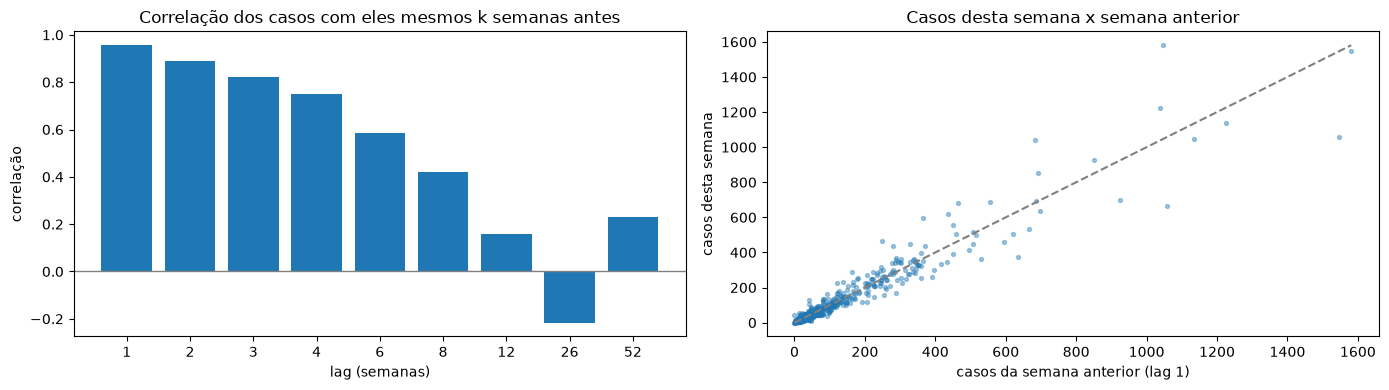

In [8]:
# Esquerda: a correlação caindo conforme o lag cresce
# Direita: casos desta semana x casos da semana anterior; a linha tracejada é "esta semana = semana passada"
fig, (eixo_lags, eixo_lag1) = plt.subplots(1, 2, figsize=(14, 4))

eixo_lags.bar(autocorrelacao["lag_semanas"].astype(str), autocorrelacao["correlacao"])
eixo_lags.axhline(0, color="gray", linewidth=1)
eixo_lags.set_title("Correlação dos casos com eles mesmos k semanas antes")
eixo_lags.set_xlabel("lag (semanas)")
eixo_lags.set_ylabel("correlação")

lag1_fechadas = dengue.loc[fechadas.index, "casos_lag1"]
eixo_lag1.scatter(lag1_fechadas, fechadas["casos_est"], s=8, alpha=0.4)
maior = fechadas["casos_est"].max()
eixo_lag1.plot([0, maior], [0, maior], linestyle="--", color="gray")
eixo_lag1.set_title("Casos desta semana x semana anterior")
eixo_lag1.set_xlabel("casos da semana anterior (lag 1)")
eixo_lag1.set_ylabel("casos desta semana")

plt.tight_layout()
plt.show()

### Conclusões da pergunta 2

- Os casos de uma semana têm correlação de 0,956 com os da semana anterior. A correlação cai devagar (0,751 com 4 semanas, 0,421 com 8) e some perto de 12 semanas (0,158): um surto sobe e desce ao longo de várias semanas.
- Com 26 semanas a correlação fica negativa (−0,216): meio ano depois de um pico é época de baixa.
- Com 52 semanas (a mesma semana do ano anterior) ela é só 0,231: o momento do pico se repete todo ano, mas o tamanho não.
- Consequência: o baseline ingênuo ("semana que vem = esta semana") vai ser difícil de bater.

## 3. Chuva e casos

Quantas semanas depois da chuva os casos sobem? Comparo os casos de cada semana com a chuva de k semanas antes (k de 0 a 16).

O cuidado aqui é que chuva e dengue têm época certa no ano: chove em fevereiro e tem dengue em abril, todo ano. Isso já daria correlação mesmo que uma não tivesse nada a ver com a outra. Por isso faço a conta duas vezes: com os valores crus, e com as anomalias (o valor da semana menos a mediana daquela semana do ano). A segunda pergunta é: um ano mais chuvoso que o normal teve mais dengue que o normal?

In [9]:
# Quantas semanas depois da chuva os casos sobem?
# Pra cada k, compara os casos desta semana com a chuva de k semanas atrás (chuva_mm.shift(k))
# Clima é o do ERA5 (as colunas sem sufixo); só semanas fechadas entram na conta
LAGS_CHUVA = list(range(0, 17))

linhas = []
for k in LAGS_CHUVA:
    chuva_k_semanas_antes = dengue["chuva_mm"].shift(k)
    correlacao = fechadas["casos_est"].corr(chuva_k_semanas_antes[fechadas.index])
    linhas.append({"lag_semanas": k, "correlacao_crua": correlacao})

chuva_x_casos = pd.DataFrame(linhas)
chuva_x_casos.round(3)

,lag_semanas,correlacao_crua
0,0,0.171
1,1,0.219
2,2,0.260
3,3,0.291
4,4,0.335
5,5,0.364
6,6,0.373
7,7,0.364
8,8,0.346
9,9,0.348


In [10]:
# Cuidado: chuva e dengue têm época certa no ano (pergunta 1). Mesmo sem nenhuma relação entre elas,
# "chove em fevereiro" e "tem dengue em abril" já dariam correlação, só por acontecerem todo ano na mesma ordem.
# Pra separar isso, tira de cada semana o valor típico daquela semana do ano (a mediana):
# sobra a "anomalia", ou seja, o quanto aquela semana ficou acima ou abaixo do normal pra época.
# Se a chuva ajuda além da época do ano, um ano mais chuvoso que o normal deveria ter mais casos que o normal.
#
# Obs.: as medianas usam o período todo. Serve pra explorar; no modelo (etapa 7) isso teria que vir só do treino.
mediana_casos_semana = fechadas.groupby("semana_do_ano")["casos_est"].median()
mediana_chuva_semana = dengue.groupby("semana_do_ano")["chuva_mm"].median()

# .map troca cada semana do ano pela mediana dela (como um JOIN com a tabela de medianas)
dengue["casos_anomalia"] = dengue["casos_est"] - dengue["semana_do_ano"].map(mediana_casos_semana)
dengue["chuva_anomalia"] = dengue["chuva_mm"] - dengue["semana_do_ano"].map(mediana_chuva_semana)

linhas = []
for k in LAGS_CHUVA:
    chuva_anomalia_k = dengue["chuva_anomalia"].shift(k)
    correlacao = dengue.loc[fechadas.index, "casos_anomalia"].corr(chuva_anomalia_k[fechadas.index])
    linhas.append(correlacao)

chuva_x_casos["correlacao_sem_epoca"] = linhas
chuva_x_casos.round(3)

,lag_semanas,correlacao_crua,correlacao_sem_epoca
0,0,0.171,-0.007
1,1,0.219,-0.012
2,2,0.260,-0.018
3,3,0.291,-0.036
4,4,0.335,-0.026
5,5,0.364,-0.015
6,6,0.373,-0.037
7,7,0.364,-0.069
8,8,0.346,-0.103
9,9,0.348,-0.092


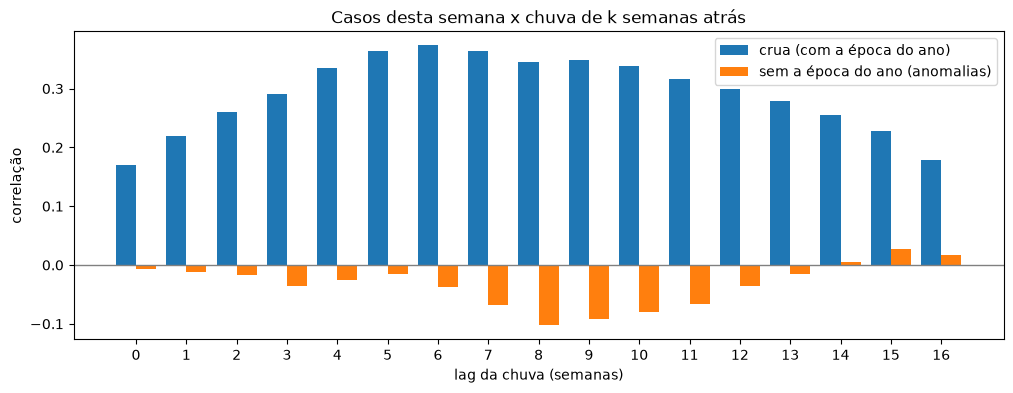

In [11]:
# As duas correlações lado a lado: a crua (com a época do ano junto) e a sem a época
fig, eixo = plt.subplots(figsize=(12, 4))

largura = 0.4
posicoes = chuva_x_casos["lag_semanas"]
eixo.bar(posicoes - largura / 2, chuva_x_casos["correlacao_crua"], width=largura, label="crua (com a época do ano)")
eixo.bar(posicoes + largura / 2, chuva_x_casos["correlacao_sem_epoca"], width=largura, label="sem a época do ano (anomalias)")
eixo.axhline(0, color="gray", linewidth=1)

eixo.set_xticks(posicoes)
eixo.set_title("Casos desta semana x chuva de k semanas atrás")
eixo.set_xlabel("lag da chuva (semanas)")
eixo.set_ylabel("correlação")
eixo.legend()
plt.show()

### Conclusões da pergunta 3

- A correlação crua sobe até 0,373 com 6 semanas de atraso (0,364 com 5 e com 7) e cai devagar depois. Parece o ciclo do mosquito.
- Mas, sem a época do ano, ela some: fica entre −0,10 e +0,03 em todos os lags. Quase toda a relação entre chuva e casos vem da sazonalidade. Uma semana mais chuvosa que o normal não veio seguida de mais dengue que o normal.
- Isso não prova que a chuva não importa. A correlação é linear (uma relação em "U", como chuva demais lavando os criadouros, não aparece), usa a chuva de uma semana só (o efeito pode estar na chuva acumulada), a chuva do ERA5 é a variável mais fraca (correlação de 0,71 com a estação), e tirar a mediana pode levar junto parte do sinal real.
- Pra etapa 7: testar a chuva acumulada de várias semanas, e não escolher o lag de 6 semanas só pela correlação crua, porque ele provavelmente carregaria a época do ano, e não a chuva.

## 4. Temperatura e umidade

A mesma análise da chuva (crua e sem a época do ano) pra temperatura média, mínima e máxima e pra umidade. Como é a mesma conta pras quatro, ela vira uma função.

In [12]:
# Mesma análise da chuva, agora pra temperatura e umidade
# Como é a mesma conta pra 4 variáveis, vira uma função (em vez de copiar o código 4 vezes)
def correlacao_por_lag(coluna):
    # Anomalia da variável: valor da semana menos a mediana daquela semana do ano
    mediana_semana = dengue.groupby("semana_do_ano")[coluna].median()
    anomalia = dengue[coluna] - dengue["semana_do_ano"].map(mediana_semana)

    linhas = []
    for k in LAGS_CHUVA:
        crua = fechadas["casos_est"].corr(dengue[coluna].shift(k)[fechadas.index])
        sem_epoca = dengue.loc[fechadas.index, "casos_anomalia"].corr(anomalia.shift(k)[fechadas.index])
        linhas.append({"lag_semanas": k, "correlacao_crua": crua, "correlacao_sem_epoca": sem_epoca})

    return pd.DataFrame(linhas)


VARIAVEIS_CLIMA = ["temp_media", "temp_min", "temp_max", "umidade_media"]

# Um dicionário: nome da variável -> tabela de correlação por lag
correlacoes_clima = {}
for variavel in VARIAVEIS_CLIMA:
    correlacoes_clima[variavel] = correlacao_por_lag(variavel)

# Resumo: em que lag cada variável tem a maior correlação (em valor absoluto), crua e sem a época
resumo = []
for variavel in VARIAVEIS_CLIMA:
    tabela = correlacoes_clima[variavel]
    linha_crua = tabela.loc[tabela["correlacao_crua"].abs().idxmax()]
    linha_sem = tabela.loc[tabela["correlacao_sem_epoca"].abs().idxmax()]
    resumo.append({
        "variavel": variavel,
        "lag_maior_crua": int(linha_crua["lag_semanas"]),
        "maior_crua": linha_crua["correlacao_crua"],
        "lag_maior_sem_epoca": int(linha_sem["lag_semanas"]),
        "maior_sem_epoca": linha_sem["correlacao_sem_epoca"],
    })

pd.DataFrame(resumo).round(3)

,variavel,lag_maior_crua,maior_crua,lag_maior_sem_epoca,maior_sem_epoca
0,temp_media,4,-0.405,16,-0.135
1,temp_min,0,-0.104,16,-0.096
2,temp_max,2,-0.419,16,-0.145
3,umidade_media,5,0.479,16,0.148


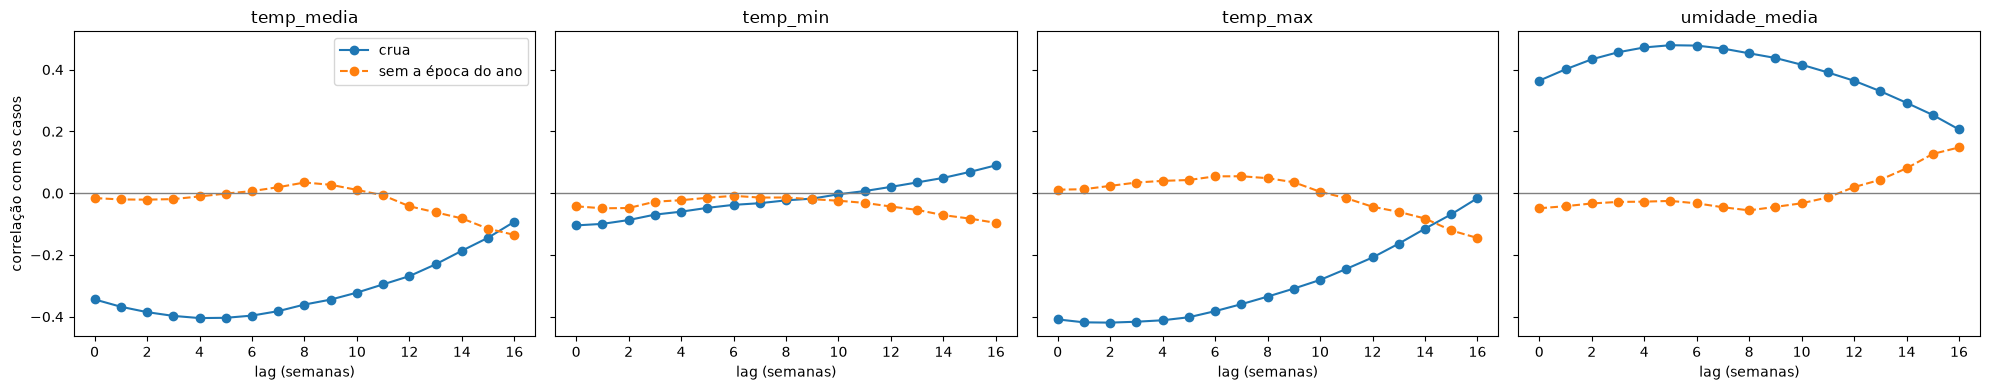

In [13]:
# Um gráfico por variável: linha cheia = crua, tracejada = sem a época do ano
fig, eixos = plt.subplots(1, 4, figsize=(20, 4), sharey=True)

for eixo, variavel in zip(eixos, VARIAVEIS_CLIMA):
    tabela = correlacoes_clima[variavel]
    eixo.plot(tabela["lag_semanas"], tabela["correlacao_crua"], marker="o", label="crua")
    eixo.plot(tabela["lag_semanas"], tabela["correlacao_sem_epoca"], marker="o", linestyle="--", label="sem a época do ano")
    eixo.axhline(0, color="gray", linewidth=1)
    eixo.set_title(variavel)
    eixo.set_xlabel("lag (semanas)")

eixos[0].set_ylabel("correlação com os casos")
eixos[0].legend()
plt.tight_layout()
plt.show()

### Conclusões da pergunta 4

- A correlação crua é forte em três delas: umidade +0,479 (5 semanas antes), temperatura máxima −0,419 (2 semanas) e temperatura média −0,405 (4 semanas). A temperatura mínima é fraca (−0,104).
- O sinal negativo da temperatura faz sentido em Teresina: a dengue vem na época chuvosa, que é a mais "fresca" do ano, e o calor forte (setembro a novembro) vem na seca. A cidade é sempre quente o bastante pro mosquito; o que limita é a água.
- Sem a época do ano, tudo some de novo: o maior valor fica entre 0,10 e 0,15, sempre com 16 semanas de atraso, na ponta da janela. Parece mais ruído ou resto da sazonalidade do que efeito real (não conferi).
- Junto com a pergunta 3: o clima semanal quase só carrega a informação da época do ano, que o modelo já pode ter pela semana do ano e pelos casos recentes. A pergunta certa pra etapa 7 é se o clima acrescenta algo além disso.

## 5. Distribuição dos casos

Os casos se espalham de forma equilibrada ou tem muita semana baixa e poucas semanas enormes? Isso decide a métrica da etapa 6 e se vale treinar o modelo numa escala transformada (log).

In [14]:
# Como os casos semanais se distribuem: muitas semanas baixas e poucas enormes?
casos_fechadas = fechadas["casos_est"]

print(casos_fechadas.describe().round(1))
print()

# Média bem acima da mediana = poucas semanas muito altas puxando a média
print("Média:", round(casos_fechadas.mean(), 1), "| Mediana:", casos_fechadas.median())

# Assimetria: 0 = simétrica; bem acima de 0 = cauda longa pra direita (poucos valores gigantes)
print("Assimetria:", round(casos_fechadas.skew(), 2))

count     599.0
mean      116.2
std       182.5
min         0.0
25%        21.0
50%        47.0
75%       132.5
max      1581.0
Name: casos_est, dtype: float64

Média: 116.2 | Mediana: 47.0
Assimetria: 3.87


In [15]:
# Quanto dos casos está concentrado nas semanas mais altas?
# sort_values(ascending=False) = ORDER BY casos_est DESC
do_maior_pro_menor = casos_fechadas.sort_values(ascending=False)
dez_por_cento = int(len(casos_fechadas) * 0.10)
semanas_do_topo = do_maior_pro_menor.head(dez_por_cento)

percentual_dos_casos = semanas_do_topo.sum() / casos_fechadas.sum() * 100
print("As", dez_por_cento, "semanas mais altas (10%) têm", round(percentual_dos_casos, 1), "% de todos os casos")

# Quantas dessas semanas são do surto de 2022?
anos_do_topo = fechadas.loc[semanas_do_topo.index, "data_iniSE"].dt.year
print("Dessas,", (anos_do_topo == 2022).sum(), "são de 2022")

As 59 semanas mais altas (10%) têm 45.8 % de todos os casos
Dessas, 17 são de 2022


Assimetria em log: 0.08


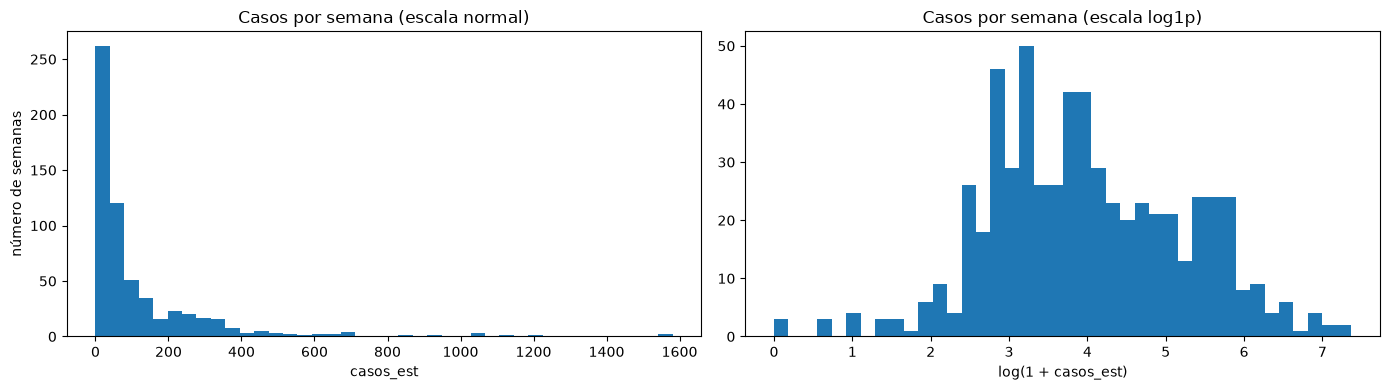

In [16]:
import numpy as np

# log1p(x) = log(1 + x): "aperta" os valores grandes e mantém o 0 como 0 (log de 0 não existe, por isso o +1)
# Na escala log, ir de 10 pra 100 casos e de 100 pra 1000 vira o mesmo "passo"
casos_log = np.log1p(casos_fechadas)
print("Assimetria em log:", round(casos_log.skew(), 2))

fig, (eixo_cru, eixo_log) = plt.subplots(1, 2, figsize=(14, 4))

eixo_cru.hist(casos_fechadas, bins=40)
eixo_cru.set_title("Casos por semana (escala normal)")
eixo_cru.set_xlabel("casos_est")
eixo_cru.set_ylabel("número de semanas")

eixo_log.hist(casos_log, bins=40)
eixo_log.set_title("Casos por semana (escala log1p)")
eixo_log.set_xlabel("log(1 + casos_est)")

plt.tight_layout()
plt.show()

### Conclusões da pergunta 5

- Cauda longa: a mediana é 47 casos por semana, a média é 116,2 e o máximo é 1.581. A assimetria é 3,87.
- As 59 semanas mais altas (10%) concentram 45,8% de todos os casos, e 17 delas são de 2022.
- Em escala log (`log1p`), a assimetria cai pra 0,08: a distribuição fica quase simétrica.
- Pra métrica (etapa 6): o RMSE vai ser dominado pelos picos, principalmente os de 2022, e o MAE pesa todas as semanas igual. Faz sentido reportar os dois.
- Pra etapa 7: treinar em `log1p(casos_est)` é um candidato, sempre voltando pra escala real com `expm1` antes de calcular o erro.

## 6. O surto de 2022

Três perguntas curtas sobre o maior surto da série: onde ele cai (o que importa pro corte treino/teste da etapa 6), se o clima do começo de 2022 foi diferente, e como foi a subida comparada com um ano típico.

In [17]:
# Onde o surto de 2022 cai na série? Isso importa pro corte treino/teste da etapa 6
# Pra cada semana fechada: que fração da série já passou até ela (1/599, 2/599, ...)
posicao = pd.Series(range(1, len(fechadas) + 1), index=fechadas.index)
fechadas["fracao_da_serie"] = posicao / len(fechadas)

fim_2022 = fechadas.loc[fechadas["ano"] == 2022, "fracao_da_serie"].max()
print("O fim de 2022 está em", round(fim_2022 * 100, 1), "% das semanas fechadas")
print()

# Se o treino ficasse com os primeiros 70%, 80% ou 90% da série, em que data o teste começaria?
for fracao_treino in [0.7, 0.8, 0.9]:
    primeira_do_teste = fechadas[fechadas["fracao_da_serie"] > fracao_treino].iloc[0]
    print(f"Treino com {int(fracao_treino * 100)}% -> teste começa em", primeira_do_teste["data_iniSE"].date())

print("Última semana fechada:", fechadas["data_iniSE"].max().date())

O fim de 2022 está em 69.6 % das semanas fechadas

Treino com 70% -> teste começa em 2023-01-15
Treino com 80% -> teste começa em 2024-03-10
Treino com 90% -> teste começa em 2025-05-04
Última semana fechada: 2026-06-21


In [18]:
# O clima do começo de 2022 foi diferente? Compara jan-mar (semanas 1 a 13) de cada ano com os casos do ano
comeco_do_ano = fechadas[fechadas["semana_do_ano"] <= 13]

por_ano = comeco_do_ano.groupby("ano").agg(
    chuva_jan_mar=("chuva_mm", "sum"),
    umidade_jan_mar=("umidade_media", "mean"),
    temp_jan_mar=("temp_media", "mean"),
    casos_jan_mar=("casos_est", "sum"),
)
por_ano["casos_no_ano"] = fechadas.groupby("ano")["casos_est"].sum()

# Posição de 2022 em cada coluna (1 = o maior valor entre os anos)
print("Posição de 2022 (1 = maior):")
print(por_ano.rank(ascending=False).loc[2022])
print()

# Correlação entre anos (2026 fica fora: o ano ainda não terminou)
# São só 11 anos, então isso é uma pista, não uma prova
anos_completos = por_ano.drop(index=2026)
print("Correlação com os casos do ano, entre os 11 anos completos:")
print("  chuva jan-mar:", round(anos_completos["chuva_jan_mar"].corr(anos_completos["casos_no_ano"]), 2))
print("  umidade jan-mar:", round(anos_completos["umidade_jan_mar"].corr(anos_completos["casos_no_ano"]), 2))
print("  casos jan-mar:", round(anos_completos["casos_jan_mar"].corr(anos_completos["casos_no_ano"]), 2))

por_ano.round(1)

Posição de 2022 (1 = maior):
chuva_jan_mar       7.0
umidade_jan_mar     1.0
temp_jan_mar       11.0
casos_jan_mar       1.0
casos_no_ano        1.0
Name: 2022, dtype: float64

Correlação com os casos do ano, entre os 11 anos completos:
  chuva jan-mar: -0.27
  umidade jan-mar: 0.09
  casos jan-mar: 0.95


,chuva_jan_mar,umidade_jan_mar,temp_jan_mar,casos_jan_mar,casos_no_ano
ano,,,,,
2015,704.7,79.7,27.5,2632.0,6394.0
2016,916.6,82.5,27.8,1230.0,4368.0
2017,843.8,83.8,27.2,979.0,4338.0
2018,944.2,83.1,27.0,568.0,1492.0
2019,669.2,84.9,27.1,1019.0,5458.0
2020,943.0,84.7,26.9,503.0,1245.0
2021,693.0,83.3,26.8,184.0,1217.0
2022,776.8,85.0,26.8,4619.0,16170.0
2023,852.7,84.4,26.1,2185.0,5531.0


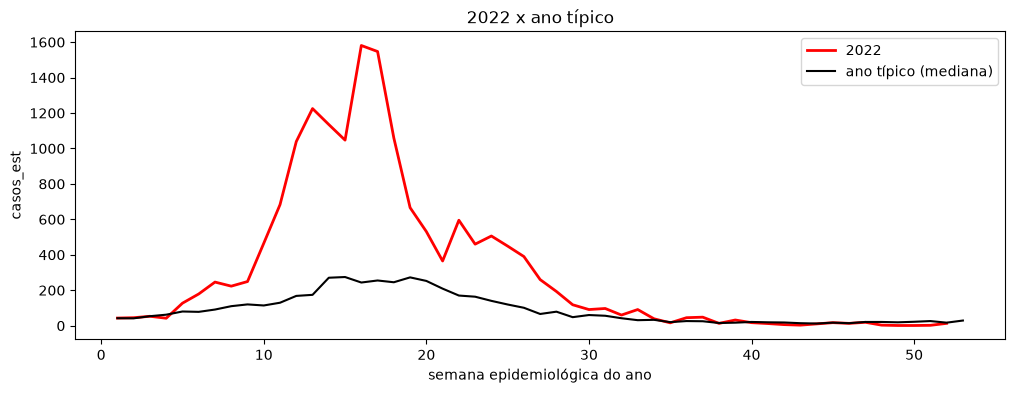

,semana_do_ano,casos_est,ano_tipico,vezes_o_tipico
365,1,43.0,42.0,1.0
366,2,45.0,41.5,1.1
367,3,53.0,53.5,1.0
368,4,42.0,62.0,0.7
369,5,127.0,80.0,1.6
370,6,179.0,78.0,2.3
371,7,246.0,91.0,2.7
372,8,223.0,110.0,2.0
373,9,249.0,120.0,2.1
374,10,465.0,114.0,4.1


In [19]:
# Como foi a subida de 2022 comparada com um ano típico (a mediana de cada semana, da pergunta 1)?
ano_2022 = fechadas[fechadas["ano"] == 2022]

fig, eixo = plt.subplots(figsize=(12, 4))
eixo.plot(ano_2022["semana_do_ano"], ano_2022["casos_est"], color="red", linewidth=2, label="2022")
eixo.plot(mediana_semana.index, mediana_semana.values, color="black", label="ano típico (mediana)")
eixo.set_title("2022 x ano típico")
eixo.set_xlabel("semana epidemiológica do ano")
eixo.set_ylabel("casos_est")
eixo.legend()
plt.show()

# Semana a semana, quantas vezes os casos de 2022 ficaram acima do ano típico (até a semana 20)
comparacao_2022 = ano_2022[["semana_do_ano", "casos_est"]].copy()
comparacao_2022["ano_tipico"] = comparacao_2022["semana_do_ano"].map(mediana_semana)
comparacao_2022["vezes_o_tipico"] = comparacao_2022["casos_est"] / comparacao_2022["ano_tipico"]
comparacao_2022[comparacao_2022["semana_do_ano"] <= 20].round(1)

### Conclusões da pergunta 6

- O fim de 2022 está em 69,6% das semanas fechadas. Com 70%, 80% ou 90% da série no treino, o teste começaria em 15/01/2023, 10/03/2024 ou 04/05/2025. Ou seja, qualquer corte simples deixa 2022 no treino e o teste sem nenhum surto daquele tamanho. Pra 2022 estar no teste, o treino ficaria só com 2015–2021, que inclui os anos fracos de covid. Isso precisa ser resolvido na etapa 6.
- O clima de janeiro a março de 2022 não foi fora do normal: a chuva foi a 7ª de 12 anos e a temperatura a 11ª (mais fresca que quase todos). A umidade foi a 1ª, mas empatada com 2019 (85,0 contra 84,9).
- Entre os 11 anos completos, a chuva de janeiro a março tem correlação de −0,27 com os casos do ano e a umidade, 0,09. São só 11 anos, então é uma pista, não uma prova.
- O surto apareceu nos próprios casos antes do pico: 2,3 vezes o ano típico na semana 6, 4,1 vezes na semana 10 e 7,0 vezes na semana 13. E os casos de janeiro a março têm correlação de 0,95 com o total do ano.
- A causa do surto (sorotipo, imunidade da população, etc.) não está nos dados; não dá pra afirmar.

## Conclusões da EDA

1. **Sazonalidade forte:** 62% dos casos entre março e maio, com o pico quase sempre nas mesmas semanas.
2. **Memória forte:** correlação de 0,956 com a semana anterior. O baseline ingênuo vai ser difícil de bater.
3. **O clima semanal quase só carrega a época do ano:** a correlação crua chega a 0,48, mas fica abaixo de 0,15 depois de tirar a sazonalidade.
4. **Cauda longa:** 10% das semanas têm 46% dos casos. MAE e RMSE juntos, e `log1p` como candidato pro alvo.
5. **2022 é um surto que o clima não explica**, que já aparecia nos casos em fevereiro e que cai no treino em qualquer corte simples.

Até aqui, o que melhor indica a dengue em Teresina é a própria dengue: os casos recentes e a época do ano. O clima ainda vai ser testado na etapa 7, com a chuva acumulada.